# Projet — Analyse intelligente des offres d'emploi (NLP, graphes et Graph-RAG)

**Version enrichie du notebook initial**

## Objectif
Exploiter les offres d'emploi Data pour analyser les tendances du marché, classifier les postes, extraire/enrichir les compétences, construire un graphe hétérogène Entreprises–Postes–Compétences, détecter des communautés, expérimenter un GNN, recommander des compétences et répondre à des questions à partir du graphe.

## Important : limites du dataset
Le dataset `lukebarousse/data_jobs` fournit notamment des titres, entreprises, pays, compétences structurées, dates et salaires selon les lignes. Il ne fournit pas nécessairement un texte libre complet de description d'offre. Le notebook vérifie les colonnes disponibles :
- si une colonne de description existe, le module NER extrait les organisations et compétences depuis ce texte ;
- sinon, le notebook exploite les champs structurés `company_name`, `job_title` et `job_skills`. Cela constitue une extraction/normalisation d'entités à partir des champs structurés, **pas un NER complet sur descriptions**. Pour revendiquer un vrai NER sur texte libre, il faudra ajouter un dataset contenant les descriptions.

## Exécution
Exécuter toutes les cellules dans l'ordre. Le premier chargement peut télécharger le dataset et le modèle SBERT. Le GNN utilise PyTorch natif pour éviter une installation fragile de PyTorch Geometric. Pour réduire la RAM, la taille d'échantillon est paramétrable dans la cellule de configuration.

## Dépendances
Le notebook vise Google Colab ou un environnement Python récent. Les résultats chiffrés sont produits à l'exécution et ne sont pas préremplis.

## 0. Installation et configuration

In [ ]:
# Dans Google Colab/Jupyter : exécuter une seule fois si nécessaire.
%pip -q install datasets sentence-transformers gensim spacy networkx scikit-learn seaborn wordcloud pandas numpy matplotlib joblib streamlit
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, ast, gc, json, math, random, warnings
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import spacy
import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, silhouette_score, adjusted_rand_score,
    normalized_mutual_info_score, homogeneity_score,
    roc_auc_score, average_precision_score
)
from sklearn.neighbors import NearestNeighbors
from wordcloud import WordCloud, STOPWORDS
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100)

# Paramètres modifiables
SAMPLE_SIZE = 20000       # mettre None pour exploiter toutes les lignes (RAM/temps plus élevés)
SBERT_MODEL = "all-MiniLM-L6-v2"
N_COMPANIES_GRAPH = 150
N_SKILLS_GRAPH = 60
MIN_EDGE_SUPPORT = 3
TOP_SKILLS_NER = 300

## 1. Chargement et exploration du dataset

In [ ]:
ds = load_dataset("lukebarousse/data_jobs", split="train")
print(ds)
df = ds.to_pandas()
print("Dimensions :", df.shape)
print("Colonnes disponibles :", df.columns.tolist())
display(df.head(3).T)

README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

data_jobs.csv: reconstructing file:   0%|          |  0.00B /  231MB            

data_jobs.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/785741 [00:00<?, ? examples/s]

Dataset({
    features: ['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills'],
    num_rows: 785741
})
Dimensions : (785741, 17)
Colonnes disponibles : ['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills']


,0,1,2
job_title_short,Senior Data Engineer,Data Analyst,Data Engineer
job_title,Senior Clinical Data Engineer / Principal Clinical Data Engineer ...,Data Analyst,"Data Engineer/Scientist/Analyst, Mid or Senior (m/f/x)"
job_location,"Watertown, CT","Guadalajara, Jalisco, Mexico","Berlin, Germany"
job_via,via Work Nearby,via BeBee México,via LinkedIn
job_schedule_type,Full-time,Full-time,Full-time
job_work_from_home,False,False,False
search_location,"Texas, United States",Mexico,Germany
job_posted_date,2023-06-16 13:44:15,2023-01-14 13:18:07,2023-10-10 13:14:55
job_no_degree_mention,False,False,False
job_health_insurance,False,False,False


In [ ]:
# Colonnes de base et colonnes complémentaires présentes dans la version du dataset
base_cols = ["job_title_short", "job_title", "job_skills", "job_country", "company_name"]
extra_candidates = [
    "job_posted_date", "salary_year_avg", "salary_hour_avg", "salary_rate",
    "job_schedule_type", "job_work_from_home", "job_via", "job_location",
    "job_description", "description", "job_text"
]
selected_cols = [c for c in base_cols + extra_candidates if c in df.columns]
df_small = df[selected_cols].copy()

required = [c for c in ["job_title", "job_skills", "company_name"] if c in df_small.columns]
df_small = df_small.dropna(subset=required)
if SAMPLE_SIZE is not None and len(df_small) > SAMPLE_SIZE:
    df_small = df_small.sample(SAMPLE_SIZE, random_state=SEED)
df_small = df_small.reset_index(drop=True)
del df, ds
gc.collect()

print("Échantillon :", df_small.shape)
print("Entreprises distinctes :", df_small["company_name"].nunique())
display(df_small.head())

Échantillon : (20000, 13)
Entreprises distinctes : 12251


,job_title_short,job_title,job_skills,job_country,company_name,job_posted_date,salary_year_avg,salary_hour_avg,salary_rate,job_schedule_type,job_work_from_home,job_via,job_location
0,Data Scientist,Data Scientist,"['r', 'python', 'matlab', 'scala', 'java', 'c#', 'c++', 'sql']",Thailand,KASIKORNBANK,2023-11-27 11:08:18,NaN,NaN,None,Full-time,False,via LinkedIn,"Bangkok, Thailand"
1,Senior Data Scientist,NL] Price,"['excel', 'power bi']",Chile,dunnhumby,2023-07-04 22:29:11,NaN,NaN,None,Full-time,False,via BeBee Chile,"Santiago, Chile"
2,Business Analyst,Frss Cr Head Count and Productivity Analyst,"['sharepoint', 'excel', 'powerpoint']",Costa Rica,Citi,2023-12-21 15:28:48,NaN,NaN,None,Full-time,False,via BeBee Costa Rica,"Heredia Province, Heredia, Costa Rica"
3,Business Analyst,Marketing Analyst,"['python', 'sql', 'r', 'snowflake', 'airflow', 'pandas', 'numpy', 'scikit-learn', 'looker', 'tab...",Germany,Taxfix SE,2023-11-30 15:17:56,NaN,NaN,None,Full-time,False,via BeBee,Germany
4,Senior Data Engineer,Senior Data Engineer,"['python', 'java', 'aws', 'azure', 'redshift', 'kafka']",Portugal,diconium GmbH,2023-04-17 14:26:24,NaN,NaN,None,Full-time,False,via Empregos Trabajo.org,"Lisbon, Portugal"


### 1.1 Préparation et normalisation
Les compétences sont transformées en listes, dédoublonnées et normalisées. Les noms d'entreprises et titres sont également nettoyés. Les champs date/salaire sont conservés s'ils existent.

In [ ]:
def parse_skills(value):
    if isinstance(value, list):
        raw = value
    elif isinstance(value, (tuple, set)):
        raw = list(value)
    elif pd.isna(value):
        return []
    else:
        try:
            raw = ast.literal_eval(str(value))
            if not isinstance(raw, (list, tuple, set)):
                raw = [raw]
        except Exception:
            # Fallback si le champ n'est pas une représentation Python de liste
            raw = re.split(r"[,;|]", str(value))
    cleaned = []
    for item in raw:
        s = re.sub(r"\s+", " ", str(item).strip().lower())
        if s and s not in {"nan", "none", "null"}:
            cleaned.append(s)
    return list(dict.fromkeys(cleaned))

def clean_company(x):
    if pd.isna(x): return None
    return re.sub(r"\s+", " ", str(x)).strip()

df_small["skills_list"] = df_small["job_skills"].apply(parse_skills)
df_small["company_name"] = df_small["company_name"].apply(clean_company)
df_small["job_title"] = df_small["job_title"].astype(str).str.strip()
df_small["job_title_short"] = df_small["job_title_short"].fillna("Unknown").astype(str).str.strip()
df_small = df_small[(df_small["skills_list"].str.len() > 0) & df_small["company_name"].notna()]
df_small = df_small.reset_index(drop=True)

df_small["skills_set"] = df_small["skills_list"].apply(frozenset)
df_small["title_clean"] = df_small["job_title"].str.lower().str.replace(r"[^\w\s+#.]", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

print(f"{len(df_small):,} offres retenues")
display(df_small[["job_title", "job_title_short", "company_name", "skills_list"]].head())

20,000 offres retenues


,job_title,job_title_short,company_name,skills_list
0,Data Scientist,Data Scientist,KASIKORNBANK,"[r, python, matlab, scala, java, c#, c++, sql]"
1,NL] Price,Senior Data Scientist,dunnhumby,"[excel, power bi]"
2,Frss Cr Head Count and Productivity Analyst,Business Analyst,Citi,"[sharepoint, excel, powerpoint]"
3,Marketing Analyst,Business Analyst,Taxfix SE,"[python, sql, r, snowflake, airflow, pandas, numpy, scikit-learn, looker, tableau, qlik]"
4,Senior Data Engineer,Senior Data Engineer,diconium GmbH,"[python, java, aws, azure, redshift, kafka]"


,taux_manquant
salary_hour_avg,98.6%
salary_year_avg,97.0%
salary_rate,95.5%
job_schedule_type,1.5%
job_location,0.1%
job_country,0.0%
job_skills,0.0%
job_title_short,0.0%
company_name,0.0%
job_posted_date,0.0%


,nombre_offres
job_title_short,
Data Engineer,5093
Data Analyst,4791
Data Scientist,4328
Senior Data Engineer,1229
Software Engineer,1165
Business Analyst,1078
Senior Data Scientist,965
Senior Data Analyst,734
Machine Learning Engineer,353


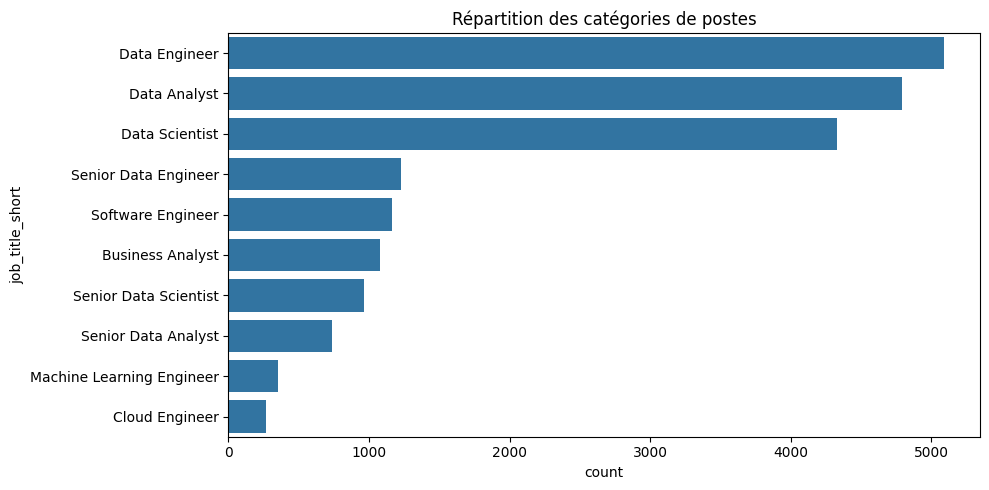

In [ ]:
# Vérification des valeurs manquantes et catégories
missing = df_small.isna().mean().sort_values(ascending=False).rename("taux_manquant")
display(missing.to_frame().style.format("{:.1%}"))
display(df_small["job_title_short"].value_counts().to_frame("nombre_offres").head(15))

plt.figure(figsize=(10,5))
sns.countplot(data=df_small, y="job_title_short",
              order=df_small["job_title_short"].value_counts().index)
plt.title("Répartition des catégories de postes")
plt.tight_layout()
plt.show()

## 2. Tendances du marché de l'emploi

Cette partie couvre explicitement l'objectif d'analyse des tendances : catégories, compétences, localisation, dates et salaires lorsque ces champs existent. Les tendances temporelles ne doivent être interprétées que si les dates sont disponibles et correctement parsées.

,competence,nb_offres,part_offres_pct
0,sql,11461,57.30
1,python,11455,57.28
2,aws,4405,22.02
3,azure,3971,19.86
4,r,3840,19.20
5,tableau,3743,18.72
6,excel,3722,18.61
7,spark,3417,17.08
8,power bi,2920,14.60
9,java,2537,12.68


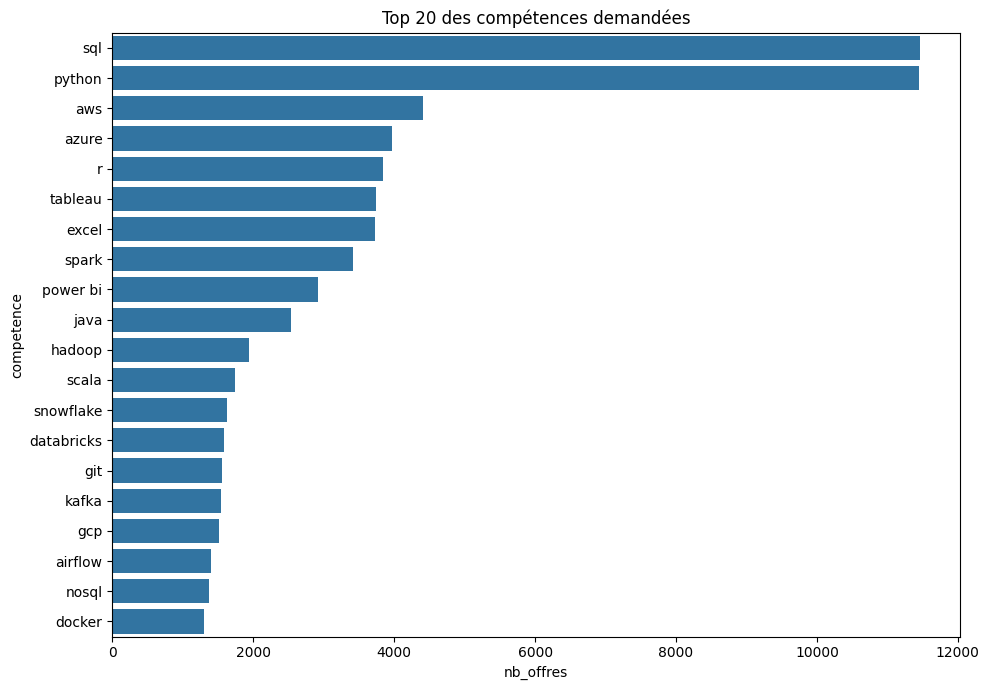

In [ ]:
# Compétences les plus fréquentes
freq_skills = Counter(s for skills in df_small["skills_list"] for s in set(skills))
top_skills_df = pd.DataFrame(freq_skills.most_common(25), columns=["competence", "nb_offres"])
top_skills_df["part_offres_pct"] = (top_skills_df["nb_offres"] / len(df_small) * 100).round(2)
display(top_skills_df)

plt.figure(figsize=(10,7))
sns.barplot(data=top_skills_df.head(20), x="nb_offres", y="competence")
plt.title("Top 20 des compétences demandées")
plt.tight_layout()
plt.show()

,nombre_offres
job_country,
United States,5396
India,1359
United Kingdom,1018
France,993
Spain,693
Germany,660
Singapore,651
Sudan,542
Netherlands,509


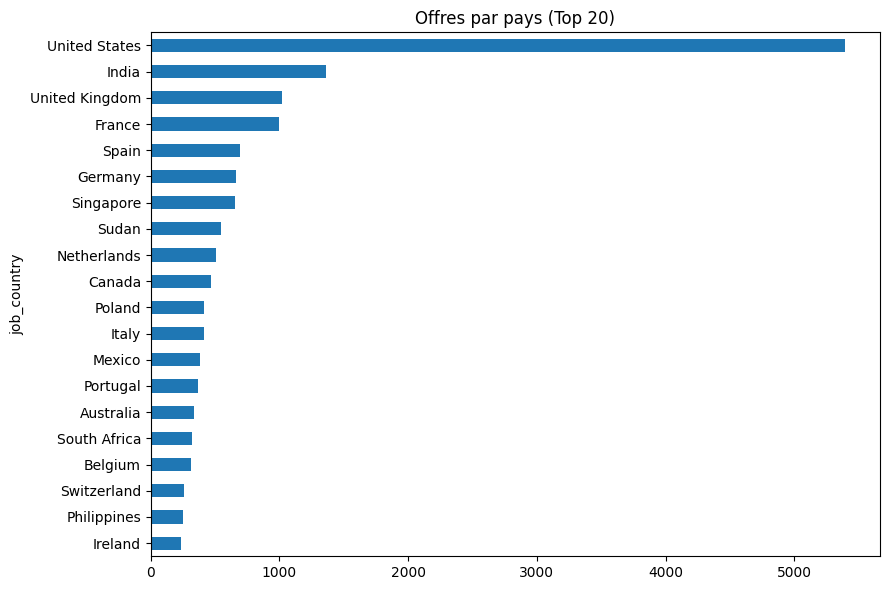

,nombre_offres
month,
2023-01,2387
2023-02,1537
2023-03,1618
2023-04,1629
2023-05,1306
2023-06,1711
2023-07,1636
2023-08,1937
2023-09,1542


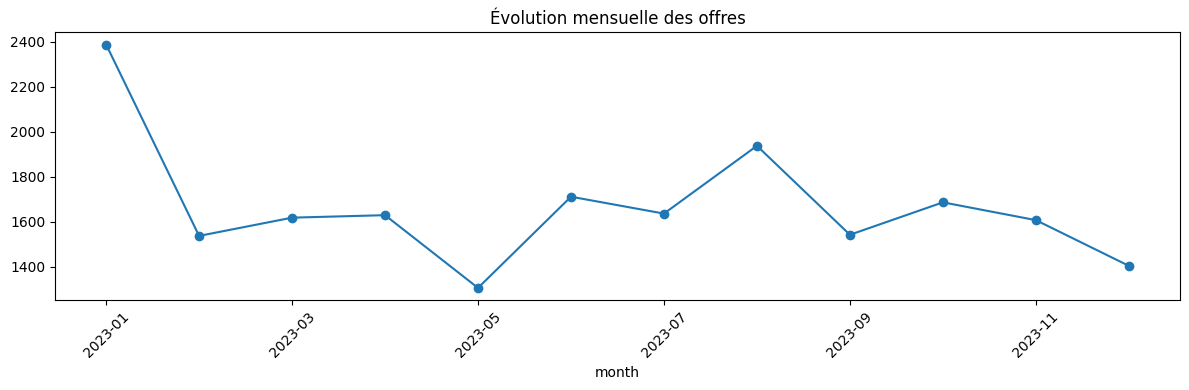

In [ ]:
# Analyse géographique
if "job_country" in df_small.columns:
    geo = df_small["job_country"].fillna("Non renseigné").value_counts().head(20)
    display(geo.to_frame("nombre_offres"))
    geo.sort_values().plot(kind="barh", figsize=(9,6), title="Offres par pays (Top 20)")
    plt.tight_layout(); plt.show()

# Tendances temporelles si la date existe
if "job_posted_date" in df_small.columns:
    df_small["posted_date"] = pd.to_datetime(df_small["job_posted_date"], errors="coerce", utc=True)
    temp = (df_small.dropna(subset=["posted_date"])
            .assign(month=lambda x: x["posted_date"].dt.to_period("M").astype(str))
            .groupby("month").size().sort_index())
    if len(temp):
        display(temp.to_frame("nombre_offres"))
        temp.plot(figsize=(12,4), marker="o", title="Évolution mensuelle des offres")
        plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    else:
        print("Aucune date exploitable dans l'échantillon.")
else:
    print("Colonne de date absente : analyse temporelle non disponible pour cette version.")

Résumé salary_year_avg


,count,median,mean
job_title_short,,,
Data Scientist,154,130982.75,136755.630834
Data Analyst,143,90000.00,95289.173077
Data Engineer,143,131580.00,133486.443346
Senior Data Engineer,55,147500.00,146430.646591
Senior Data Scientist,46,150000.00,152747.402174
Senior Data Analyst,30,111175.00,117985.983333
Business Analyst,15,87500.00,84266.666667
Software Engineer,13,90000.00,112292.307692
Machine Learning Engineer,9,89100.00,99406.444444


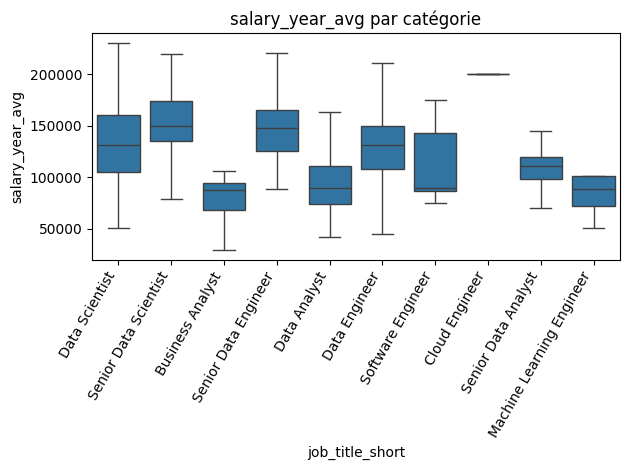

Résumé salary_hour_avg


,count,median,mean
job_title_short,,,
Data Analyst,109,33.000000,38.725826
Data Scientist,71,44.735001,45.832606
Data Engineer,67,60.000000,58.693880
Senior Data Engineer,11,67.500000,72.981363
Senior Data Analyst,10,57.500000,56.932500
Business Analyst,9,46.255001,46.438889
Senior Data Scientist,7,52.500000,54.547143
Machine Learning Engineer,1,67.500000,67.500000
Software Engineer,1,50.000000,50.000000


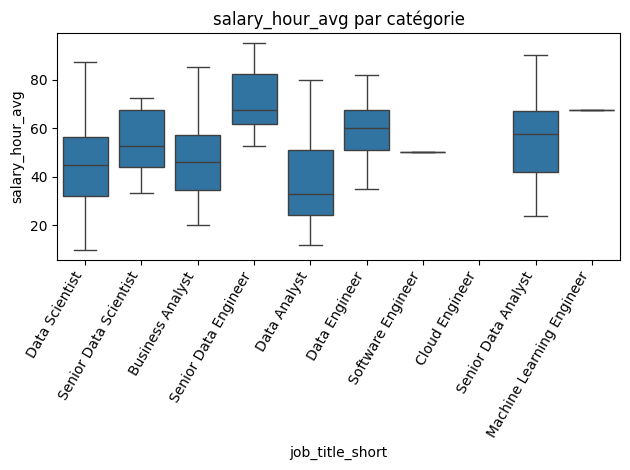

In [ ]:
# Analyse des salaires si au moins une colonne de salaire existe
salary_cols = [c for c in ["salary_year_avg", "salary_hour_avg"] if c in df_small.columns]
if salary_cols:
    for col in salary_cols:
        df_small[col] = pd.to_numeric(df_small[col], errors="coerce")
        if df_small[col].notna().sum() > 0:
            print(f"Résumé {col}")
            display(df_small.groupby("job_title_short")[col].agg(["count","median","mean"]).sort_values("count", ascending=False).head(15))
            sns.boxplot(data=df_small, x="job_title_short", y=col, showfliers=False)
            plt.xticks(rotation=60, ha="right"); plt.title(f"{col} par catégorie"); plt.tight_layout(); plt.show()
else:
    print("Colonnes de salaire absentes : ne pas inventer d'analyse salariale.")

## 3. NLP — prétraitement des titres, TF-IDF, Word2Vec et SBERT

In [ ]:
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser"])
except OSError:
    raise RuntimeError("Modèle spaCy absent. Exécuter la cellule d'installation en haut du notebook.")

def preprocess_title(text):
    doc = nlp(str(text).lower())
    tokens = []
    for tok in doc:
        if tok.is_space or tok.is_punct or tok.is_stop:
            continue
        lemma = "data" if tok.lower_ == "data" else tok.lemma_.lower()
        if lemma.strip():
            tokens.append(lemma)
    return " ".join(tokens)

df_small["title_processed"] = [preprocess_title(t) for t in df_small["job_title"]]
display(df_small[["job_title", "title_processed"]].head(10))

,job_title,title_processed
0,Data Scientist,data scientist
1,NL] Price,nl price
2,Frss Cr Head Count and Productivity Analyst,frss cr head count productivity analyst
3,Marketing Analyst,marketing analyst
4,Senior Data Engineer,senior data engineer
5,Sr. Business Intelligence Engineer,sr business intelligence engineer
6,Company Financials Analyst,company financial analyst
7,Data Scientist,data scientist
8,AWS Bigdata Data Engineer,aws bigdata data engineer
9,"Senior Software Engineer, Data Platform",senior software engineer data platform


In [ ]:
# TF-IDF : le vocabulaire est ajusté plus tard sur le TRAIN pour la classification.
# Ici, on peut ajuster un vectoriseur exploratoire sur tout l'échantillon pour visualisation seulement.
tfidf_explore = TfidfVectorizer(min_df=3, ngram_range=(1,2), max_features=30000)
X_tfidf_explore = tfidf_explore.fit_transform(df_small["title_processed"])
vocab_explore = tfidf_explore.get_feature_names_out()

for cat in df_small["job_title_short"].value_counts().index[:10]:
    idx = np.flatnonzero(df_small["job_title_short"].values == cat)
    mean_weights = np.asarray(X_tfidf_explore[idx].mean(axis=0)).ravel()
    terms = vocab_explore[np.argsort(mean_weights)[::-1][:8]]
    print(f"{cat}: {', '.join(terms)}")

Data Engineer: data engineer, engineer, data, azure, lead, lead data, azure data, big
Data Analyst: data analyst, analyst, data, business data, analytic, business, data analytic, junior
Data Scientist: data scientist, scientist, data, science, data science, lead, lead data, analytic
Senior Data Engineer: senior data, senior, data engineer, engineer, data, sr, engineer senior, remote
Software Engineer: software, software engineer, engineer, senior, senior software, developer, devops, devops engineer
Business Analyst: analyst, business, business analyst, business intelligence, intelligence, intelligence analyst, bi, bi analyst
Senior Data Scientist: senior data, senior, data scientist, scientist, data, science, data science, sr
Senior Data Analyst: senior, senior data, data analyst, analyst, data, sr, analytic, senior analyst
Machine Learning Engineer: machine, learn, machine learn, learn engineer, engineer, ml, senior machine, ml engineer
Cloud Engineer: cloud, engineer, cloud engineer,

In [ ]:
# Similarité SBERT sur les titres
sbert = SentenceTransformer(SBERT_MODEL)
titles = df_small["job_title"].astype(str).tolist()
S = sbert.encode(titles, batch_size=128, show_progress_bar=True,
                 convert_to_numpy=True, normalize_embeddings=True)
print("Matrice SBERT :", S.shape)

def similar_jobs(query, n=5):
    qv = sbert.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    sims = (S @ qv.T).ravel()
    ix = np.argsort(sims)[::-1][:n]
    return df_small.iloc[ix][["job_title","job_title_short","company_name"]].assign(similarite=sims[ix].round(3))

display(similar_jobs("machine learning engineer", 10))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Matrice SBERT : (20000, 384)


,job_title,job_title_short,company_name,similarite
4572,Machine Learning Engineer,Machine Learning Engineer,Network Engineering,1.0
4561,Machine Learning Engineer,Machine Learning Engineer,Insurance Australia Group Limited,1.0
17831,Machine Learning Engineer,Machine Learning Engineer,Allegro,1.0
881,Machine Learning Engineer,Machine Learning Engineer,Collabera Digital,1.0
9423,Machine Learning Engineer,Machine Learning Engineer,Carlysle Talent Search - Centurion,1.0
3468,Machine Learning Engineer,Machine Learning Engineer,Artemest,1.0
867,Machine Learning Engineer,Machine Learning Engineer,Saransh Inc,1.0
17116,Machine Learning Engineer,Machine Learning Engineer,Emtech Recruitment,1.0
17174,Machine Learning Engineer,Machine Learning Engineer,Digital Nova Scotia,1.0
7952,Machine Learning Engineer,Machine Learning Engineer,BenchPoint,1.0


### 3.1 Word2Vec sur les compétences
Chaque offre est considérée comme un ensemble de compétences. Word2Vec sert ici de baseline de représentation ; les compétences d'une offre ne sont pas une phrase ordonnée, donc ses limites doivent être discutées.

In [ ]:
sentences = df_small["skills_list"].tolist()
# Word2Vec exploratoire. Pour une évaluation stricte, réentraîner uniquement sur les offres du train.
w2v = Word2Vec(sentences=sentences, vector_size=100, window=10, min_count=5,
               sg=1, workers=1, epochs=15, seed=SEED)
print("Vocabulaire Word2Vec :", len(w2v.wv))

def skill_vector(skills):
    vecs = [w2v.wv[s] for s in skills if s in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

E = np.vstack([skill_vector(x) for x in sentences])
print("Vecteurs d'offres :", E.shape)

def similar_skills_w2v(skill, n=10):
    if skill not in w2v.wv:
        print("Compétence absente du vocabulaire.")
        return
    return pd.DataFrame(w2v.wv.most_similar(skill, topn=n), columns=["competence","similarite"])

display(similar_skills_w2v("python", 10) if "python" in w2v.wv else pd.DataFrame())

Vocabulaire Word2Vec : 195
Vecteurs d'offres : (20000, 100)


,competence,similarite
0,symphony,0.545819
1,wire,0.506671
2,powerbi,0.486038
3,unreal,0.485209
4,assembly,0.472728
5,julia,0.461766
6,datarobot,0.455164
7,ibm cloud,0.452974
8,jupyter,0.450535
9,unify,0.450167


## 4. Classification des postes (`job_title_short`)

**Correction méthodologique :** séparation train/test avant l'ajustement de TF-IDF et Word2Vec. SBERT est un encodeur pré-entraîné figé. Les doublons de titres sont groupés autant que possible pour limiter la fuite d'information.

In [ ]:
y = df_small["job_title_short"].astype(str).values
groups = df_small["title_clean"].values

# GroupShuffleSplit si possible ; sinon split stratifié classique.
try:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    idx_train, idx_test = next(splitter.split(df_small, y, groups=groups))
    if len(np.unique(y[idx_train])) < 2 or len(np.unique(y[idx_test])) < 2:
        raise ValueError("Classes insuffisantes dans un des sous-ensembles.")
except Exception:
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    idx_train, idx_test = next(splitter.split(df_small, y))

print("Train:", len(idx_train), "| Test:", len(idx_test))
print("Classes train/test:", len(np.unique(y[idx_train])), len(np.unique(y[idx_test])))

# TF-IDF sans fuite : fit uniquement sur train
tfidf_clf = TfidfVectorizer(min_df=2, ngram_range=(1,2), max_features=30000)
X_train_tfidf = tfidf_clf.fit_transform(df_small.iloc[idx_train]["title_processed"])
X_test_tfidf = tfidf_clf.transform(df_small.iloc[idx_test]["title_processed"])

# Word2Vec sans fuite : entraînement uniquement sur compétences train
w2v_clf = Word2Vec(sentences=[sentences[i] for i in idx_train], vector_size=100,
                   window=10, min_count=3, sg=1, workers=1, epochs=15, seed=SEED)
def w2v_offer_vector(skills, model):
    vs = [model.wv[s] for s in skills if s in model.wv]
    return np.mean(vs, axis=0) if vs else np.zeros(model.vector_size)

X_train_w2v = np.vstack([w2v_offer_vector(sentences[i], w2v_clf) for i in idx_train])
X_test_w2v = np.vstack([w2v_offer_vector(sentences[i], w2v_clf) for i in idx_test])

X_train_sbert, X_test_sbert = S[idx_train], S[idx_test]

Train: 16397 | Test: 3603
Classes train/test: 10 10


,accuracy,precision_macro,recall_macro,f1_macro
modele,,,,
SBERT titres,0.834,0.718,0.792,0.739
SBERT + Word2Vec,0.835,0.713,0.788,0.738
TF-IDF titres,0.841,0.715,0.787,0.732
Word2Vec compétences,0.286,0.273,0.321,0.246


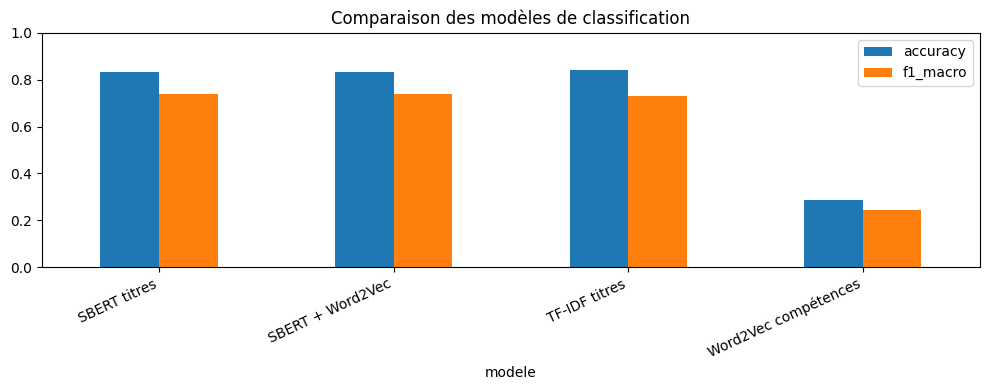

In [ ]:
feature_sets = {
    "TF-IDF titres": (X_train_tfidf, X_test_tfidf),
    "Word2Vec compétences": (X_train_w2v, X_test_w2v),
    "SBERT titres": (X_train_sbert, X_test_sbert),
    "SBERT + Word2Vec": (np.hstack([X_train_sbert, X_train_w2v]),
                         np.hstack([X_test_sbert, X_test_w2v]))
}

classifiers, predictions, rows = {}, {}, []
for name, (Xtr, Xte) in feature_sets.items():
    clf = LogisticRegression(max_iter=2500, class_weight="balanced")
    clf.fit(Xtr, y[idx_train])
    pred = clf.predict(Xte)
    classifiers[name] = clf
    predictions[name] = pred
    p, r, f1, _ = precision_recall_fscore_support(y[idx_test], pred, average="macro", zero_division=0)
    rows.append({"modele":name, "accuracy":accuracy_score(y[idx_test],pred),
                 "precision_macro":p, "recall_macro":r, "f1_macro":f1})

classification_results = pd.DataFrame(rows).set_index("modele").sort_values("f1_macro", ascending=False)
display(classification_results.round(3))
classification_results[["accuracy","f1_macro"]].plot(kind="bar", figsize=(10,4), ylim=(0,1))
plt.title("Comparaison des modèles de classification"); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

Meilleur modèle selon F1 macro : SBERT titres
                           precision    recall  f1-score   support

         Business Analyst       0.71      0.84      0.77       218
           Cloud Engineer       0.26      0.73      0.38        49
             Data Analyst       0.91      0.82      0.86       774
            Data Engineer       0.92      0.81      0.86       749
           Data Scientist       0.89      0.77      0.83       590
Machine Learning Engineer       0.56      0.71      0.63        58
      Senior Data Analyst       0.55      0.75      0.64       114
     Senior Data Engineer       0.92      0.99      0.95       743
    Senior Data Scientist       0.70      0.71      0.70       123
        Software Engineer       0.77      0.79      0.78       185

                 accuracy                           0.83      3603
                macro avg       0.72      0.79      0.74      3603
             weighted avg       0.86      0.83      0.84      3603



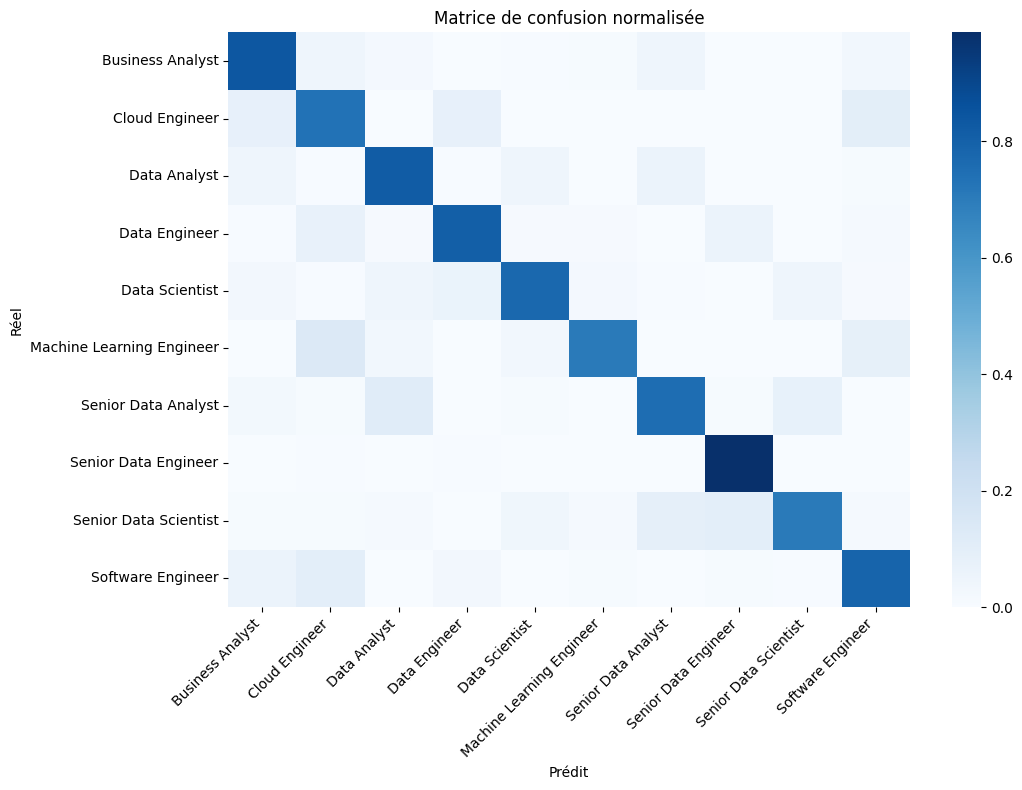

,categorie,probabilite
0,Machine Learning Engineer,0.936910
1,Senior Data Scientist,0.033302
2,Senior Data Engineer,0.012712


In [ ]:
best_name = classification_results.index[0]
best_pred = predictions[best_name]
print("Meilleur modèle selon F1 macro :", best_name)
print(classification_report(y[idx_test], best_pred, zero_division=0))

labels = sorted(np.unique(y))
cm = confusion_matrix(y[idx_test], best_pred, labels=labels, normalize="true")
plt.figure(figsize=(11,8))
sns.heatmap(cm, cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion normalisée")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

def predict_job_category(title, top_n=3):
    vec = sbert.encode([title], convert_to_numpy=True, normalize_embeddings=True)
    clf = classifiers["SBERT titres"]
    probs = clf.predict_proba(vec)[0]
    order = np.argsort(probs)[::-1][:top_n]
    return pd.DataFrame({"categorie":clf.classes_[order], "probabilite":probs[order]})

display(predict_job_category("Senior Machine Learning Engineer"))

## 5. Clustering des postes et des compétences

In [ ]:
# Clustering des postes par embeddings SBERT
X_cluster = normalize(S)
k_values = [4, 6, 8, 10, 12]
silhouette_values = []
for k in k_values:
    km_tmp = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lab = km_tmp.fit_predict(X_cluster)
    sil = silhouette_score(X_cluster, lab, sample_size=min(4000, len(X_cluster)), random_state=SEED)
    silhouette_values.append(sil)

display(pd.DataFrame({"k":k_values, "silhouette":silhouette_values}))
best_k = k_values[int(np.argmax(silhouette_values))]
job_kmeans = KMeans(n_clusters=best_k, n_init=15, random_state=SEED)
df_small["job_cluster"] = job_kmeans.fit_predict(X_cluster)

cluster_rows = []
for c, part in df_small.groupby("job_cluster"):
    skill_counts_cluster = Counter(s for skills in part["skills_list"] for s in skills)
    cluster_rows.append({
        "cluster":c, "offres":len(part),
        "categories_dominantes":", ".join(part["job_title_short"].value_counts().head(3).index),
        "titres_exemples": " | ".join(part["job_title"].head(3)),
        "competences_top":", ".join(s for s,_ in skill_counts_cluster.most_common(8))
    })
cluster_profile = pd.DataFrame(cluster_rows).set_index("cluster")
display(cluster_profile)
print("ARI:", round(adjusted_rand_score(y, df_small["job_cluster"]),3))
print("NMI:", round(normalized_mutual_info_score(y, df_small["job_cluster"]),3))

,k,silhouette
0,4,0.091360
1,6,0.104803
2,8,0.116629
3,10,0.119774
4,12,0.123851


,offres,categories_dominantes,titres_exemples,competences_top
cluster,,,,
0,2386,"Data Engineer, Senior Data Engineer, Data Scientist",Data Engineer - Remote | Data Integration Engineer | Data Engineer Lelystad,"python, sql, aws, azure, spark, java, kafka, hadoop"
1,1187,"Business Analyst, Data Scientist, Software Engineer",Frss Cr Head Count and Productivity Analyst | Marketing Analyst | Company Financials Analyst,"excel, sql, tableau, power bi, python, powerpoint, word, r"
2,2469,"Data Engineer, Data Scientist, Software Engineer",Data Engineer | Big Data Engineer | Data Engineer,"sql, python, aws, azure, spark, java, scala, hadoop"
3,2189,"Data Scientist, Senior Data Scientist, Data Analyst",Supply Chain Data Scientist | Data Science Traineeship | Data-analist inkoop,"python, sql, r, aws, tableau, spark, tensorflow, azure"
4,2108,"Senior Data Engineer, Senior Data Scientist, Senior Data Analyst","Senior Data Engineer | Senior Software Engineer, Data Platform | [Micro] Data Engineer | Senior","python, sql, aws, azure, spark, r, tableau, java"
5,1448,"Data Scientist, Data Analyst, Machine Learning Engineer",Data Scientist | Data Scientist | Researcher / Data Scientist,"python, sql, r, tableau, aws, spark, tensorflow, azure"
6,2537,"Data Analyst, Senior Data Analyst, Data Scientist",ROYALTY & DATA ANALYST - Now Hiring | Data Analyst H/F | [Job 11234] Mid-Level Data Analyst - Br...,"sql, excel, python, tableau, power bi, r, word, powerpoint"
7,752,"Data Engineer, Cloud Engineer, Senior Data Engineer",AWS Bigdata Data Engineer | Hiring for GCP Data Engineer | AWS Data Engineer,"azure, sql, python, aws, spark, databricks, gcp, java"
8,1374,"Software Engineer, Machine Learning Engineer, Business Analyst",NL] Price | Sr. Business Intelligence Engineer | Software Engineer (P-4),"python, aws, sql, java, kubernetes, azure, docker, linux"


ARI: 0.377
NMI: 0.509


In [ ]:
# Clustering des compétences fréquentes avec SBERT
skill_vocab = [s for s, n in freq_skills.most_common(100) if n >= 5]
skill_embeddings = sbert.encode(skill_vocab, batch_size=128, convert_to_numpy=True, normalize_embeddings=True)
k_skill = min(8, max(2, len(skill_vocab)//10))
skill_kmeans = KMeans(n_clusters=k_skill, n_init=15, random_state=SEED).fit(skill_embeddings)

skill_cluster_table = pd.DataFrame({"competence":skill_vocab, "cluster":skill_kmeans.labels_})
for c, part in skill_cluster_table.groupby("cluster"):
    print(f"Cluster {c}: {', '.join(part['competence'].tolist())}")

Cluster 0: aws, azure, power bi, gcp, terraform, outlook, microstrategy, bitbucket, angular, sheets
Cluster 1: r, spark, scala, snowflake, go, redshift, word, jira, looker, qlik, c, alteryx, gitlab, dax, react, spring, redis, ruby, golang, neo4j
Cluster 2: git, docker, github, jenkins, shell, unix, bash, ansible, powershell, css, perl, php
Cluster 3: kafka, airflow, kubernetes, tensorflow, flow, keras, flask, visio, django, chef
Cluster 4: tableau, hadoop, databricks, nosql, pyspark, bigquery, postgresql, mongodb, cassandra, elasticsearch, dynamodb, mongo, db2
Cluster 5: sql, sas, oracle, sql server, sap, ssis, confluence, spss, ssrs, t-sql, express, gdpr, typescript, splunk, cognos
Cluster 6: excel, java, linux, powerpoint, mysql, javascript, c++, c#, windows, vba, sharepoint, html
Cluster 7: python, pandas, pytorch, numpy, scikit-learn, matlab, jupyter, matplotlib


## 6. Extraction d'entités nommées (NER) et enrichissement des compétences

Le module ci-dessous est adaptatif. Si le dataset contient une description libre, spaCy extrait les organisations (ORG) et un PhraseMatcher recherche les compétences techniques dans le texte. Si aucune description n'est disponible, les compétences et entreprises sont récupérées depuis les colonnes structurées. Dans ce dernier cas, on ne présente pas cela comme un NER sur texte libre.

In [ ]:
description_candidates = ["job_description", "description", "job_text"]
description_col = next((c for c in description_candidates if c in df_small.columns), None)
print("Colonne de description détectée :", description_col)

# Taxonomie de compétences extraite des compétences structurées
skill_taxonomy = [s for s, _ in freq_skills.most_common(TOP_SKILLS_NER)]
from spacy.matcher import PhraseMatcher
matcher = PhraseMatcher(nlp.vocab, attr="LOWER")
patterns = [nlp.make_doc(s) for s in skill_taxonomy if s]
if patterns:
    matcher.add("TECH_SKILL", patterns)

def extract_entities_from_text(text):
    doc = nlp(str(text))
    skills_found = sorted({doc[start:end].text.lower() for _, start, end in matcher(doc)})
    orgs = sorted({ent.text.strip() for ent in doc.ents if ent.label_ == "ORG"})
    return {"skills_extracted":skills_found, "organizations_extracted":orgs}

if description_col:
    ner_sample = df_small.dropna(subset=[description_col]).head(1000).copy()
    extracted = ner_sample[description_col].apply(extract_entities_from_text)
    ner_sample["skills_extracted"] = extracted.apply(lambda x:x["skills_extracted"])
    ner_sample["organizations_extracted"] = extracted.apply(lambda x:x["organizations_extracted"])
    display(ner_sample[["job_title","company_name","skills_extracted","organizations_extracted"]].head(10))
else:
    print("Pas de description libre détectée.")
    print("Fallback structuré : company_name = entité entreprise ; job_title = poste ; job_skills = compétences.")
    structured_entities = pd.DataFrame({
        "entity_type":["COMPANY"]*3 + ["JOB_TITLE"]*3 + ["SKILL"]*6,
        "entity_value":(
            df_small["company_name"].dropna().astype(str).head(3).tolist() +
            df_small["job_title"].dropna().astype(str).head(3).tolist() +
            [s for s,_ in freq_skills.most_common(6)]
        )
    })
    display(structured_entities)

Colonne de description détectée : None
Pas de description libre détectée.
Fallback structuré : company_name = entité entreprise ; job_title = poste ; job_skills = compétences.


,entity_type,entity_value
0,COMPANY,KASIKORNBANK
1,COMPANY,dunnhumby
2,COMPANY,Citi
3,JOB_TITLE,Data Scientist
4,JOB_TITLE,NL] Price
5,JOB_TITLE,Frss Cr Head Count and Productivity Analyst
6,SKILL,sql
7,SKILL,python
8,SKILL,aws
9,SKILL,azure


In [ ]:
# Évaluation NER : créer un petit jeu de vérité terrain annoté manuellement.
# Exporter un échantillon, remplir la colonne gold_skills (liste Python) puis recharger le CSV.
ner_columns = ["job_title","company_name"]
if description_col:
    ner_columns.append(description_col)
ner_eval_sample = df_small[ner_columns].sample(min(100, len(df_small)), random_state=SEED).copy()
if description_col:
    ner_eval_sample["predicted_skills"] = ner_eval_sample[description_col].apply(
        lambda txt: extract_entities_from_text(txt)["skills_extracted"]
    )
else:
    ner_eval_sample["predicted_skills"] = ""
ner_eval_sample["gold_skills"] = ""
ner_eval_sample.to_csv("ner_annotation_template.csv", index=False)
print("Template créé : ner_annotation_template.csv")
print("Annoter gold_skills manuellement. Les prédictions sont dans predicted_skills.")

Template créé : ner_annotation_template.csv
Annoter gold_skills manuellement. Les prédictions sont dans predicted_skills.


In [ ]:
# À exécuter après annotation du fichier ner_annotation_completed.csv.
annotation_file = "ner_annotation_completed.csv"
if os.path.exists(annotation_file):
    ann = pd.read_csv(annotation_file)
    def to_set(v):
        try: return set(parse_skills(v))
        except Exception: return set()
    tp = fp = fn = 0
    for _, row in ann.iterrows():
        gold = to_set(row.get("gold_skills", ""))
        pred = to_set(row.get("predicted_skills", ""))
        tp += len(gold & pred); fp += len(pred-gold); fn += len(gold-pred)
    prec = tp/(tp+fp) if tp+fp else 0
    rec = tp/(tp+fn) if tp+fn else 0
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0
    print({"precision":prec, "recall":rec, "f1":f1})
else:
    print("Annotation non fournie : métriques NER non calculées.")

Annotation non fournie : métriques NER non calculées.


In [ ]:
# Enrichissement sémantique : trouver les compétences les plus proches avec SBERT
def enrich_skills(skill, top_n=8, min_similarity=0.45):
    if skill not in skill_vocab:
        candidates = skill_vocab + [skill]
        vectors = sbert.encode(candidates, convert_to_numpy=True, normalize_embeddings=True)
        q = vectors[-1]
        base_vectors = vectors[:-1]
    else:
        q = sbert.encode([skill], convert_to_numpy=True, normalize_embeddings=True)[0]
        base_vectors = skill_embeddings
        candidates = skill_vocab
    sims = base_vectors @ q
    order = np.argsort(sims)[::-1]
    rows = [{"competence_candidate":candidates[i], "similarite":float(sims[i])}
            for i in order if candidates[i].lower()!=skill.lower() and sims[i]>=min_similarity][:top_n]
    return pd.DataFrame(rows)

display(enrich_skills("machine learning", 10))

""


## 7. Construction du graphe hétérogène Entreprises–Postes–Compétences

Le graphe est **hétérogène / tripartite** : trois types de nœuds et plusieurs types de relations. Les liens entreprise–poste et poste–compétence répondent directement au sujet ; entreprise–compétence est une relation dérivée utile pour l'exploration. Les poids conservent le support (nombre d'offres) et une association PMI positive.

In [ ]:
ENT_EXCLUDED = {"confidential", "confidencial", "confidentiel", "undisclosed", "unknown"}
company_counts = df_small["company_name"].value_counts()
company_counts = company_counts[~company_counts.index.str.lower().str.strip().isin(ENT_EXCLUDED)]
top_companies = company_counts.head(N_COMPANIES_GRAPH).index.tolist()
top_graph_skills = [s for s,_ in freq_skills.most_common(N_SKILLS_GRAPH)]
top_graph_skill_set = set(top_graph_skills)

graph_df = df_small[df_small["company_name"].isin(top_companies)].copy().reset_index(drop=True)
graph_df["skills_graph"] = graph_df["skills_list"].apply(lambda xs:[s for s in xs if s in top_graph_skill_set])
graph_df["offer_id"] = np.arange(len(graph_df))
print("Offres du graphe:",len(graph_df),
      "| entreprises:",graph_df["company_name"].nunique(),
      "| compétences:",len(top_graph_skill_set))

def pair_stats(pairs_df, left, right, total_offers, min_support=MIN_EDGE_SUPPORT):
    if pairs_df.empty: return pd.DataFrame(columns=[left,right,"count","pmi"])
    ca = pairs_df.groupby(left)["offer_id"].nunique()
    cb = pairs_df.groupby(right)["offer_id"].nunique()
    joint = pairs_df.groupby([left,right])["offer_id"].nunique().rename("count").reset_index()
    joint["pmi"] = np.log((joint["count"]*total_offers) /
                          (joint[left].map(ca)*joint[right].map(cb)))
    return joint[(joint["count"]>=min_support) & (joint["pmi"]>0)].copy()

exploded = (graph_df[["offer_id","company_name","job_title_short","skills_graph"]]
            .explode("skills_graph").dropna(subset=["skills_graph"])
            .rename(columns={"skills_graph":"skill"}))

ep = pair_stats(graph_df[["offer_id","company_name","job_title_short"]].drop_duplicates(),
                "company_name","job_title_short",len(graph_df))
ps = pair_stats(exploded[["offer_id","job_title_short","skill"]].drop_duplicates(),
                "job_title_short","skill",len(graph_df))
es = pair_stats(exploded[["offer_id","company_name","skill"]].drop_duplicates(),
                "company_name","skill",len(graph_df))

B = nx.Graph()
for company, count in graph_df["company_name"].value_counts().items():
    B.add_node(f"E:{company}", node_type="company", label=str(company), offers=int(count))
for job, count in graph_df["job_title_short"].value_counts().items():
    B.add_node(f"J:{job}", node_type="job", label=str(job), offers=int(count))
for skill, count in exploded.groupby("skill")["offer_id"].nunique().items():
    B.add_node(f"S:{skill}", node_type="skill", label=str(skill), offers=int(count))

def add_relation_edges(table, left_prefix, right_prefix, left_col, right_col, relation):
    for row in table.itertuples(index=False):
        a = getattr(row,left_col); b = getattr(row,right_col)
        B.add_edge(f"{left_prefix}:{a}", f"{right_prefix}:{b}",
                   relation=relation, count=int(row.count),
                   pmi=float(row.pmi), weight=float(max(row.pmi,0.001)))

add_relation_edges(ep,"E","J","company_name","job_title_short","offers")
add_relation_edges(ps,"J","S","job_title_short","skill","requires")
add_relation_edges(es,"E","S","company_name","skill","demands")

B.remove_nodes_from(list(nx.isolates(B)))
print(nx.info(B) if hasattr(nx,"info") else f"{B.number_of_nodes()} nodes / {B.number_of_edges()} edges")
print("Types:",Counter(nx.get_node_attributes(B,"node_type").values()))
print("Relations:",Counter(d["relation"] for _,_,d in B.edges(data=True)))

Offres du graphe: 3272 | entreprises: 150 | compétences: 60
220 nodes / 1904 edges
Types: Counter({'company': 150, 'skill': 60, 'job': 10})
Relations: Counter({'demands': 1399, 'offers': 280, 'requires': 225})


In [ ]:
# Statistiques et centralités
node_types = nx.get_node_attributes(B, "node_type")
components = sorted(nx.connected_components(B), key=len, reverse=True)
print("Composantes connexes:",len(components),
      "| composante principale:",len(components[0]) if components else 0)
print("Densité:",round(nx.density(B),4))

centrality_rows = []
degree_weighted = dict(B.degree(weight="count"))
for node, data in B.nodes(data=True):
    centrality_rows.append({"node":node,"type":data["node_type"],"label":data["label"],
                            "degree":B.degree(node),"weighted_degree":degree_weighted[node]})
centrality_df = pd.DataFrame(centrality_rows).sort_values("weighted_degree",ascending=False)
display(centrality_df.groupby("type").head(10))

Composantes connexes: 1 | composante principale: 220
Densité: 0.079


,node,type,label,degree,weighted_degree
150,J:Data Engineer,job,Data Engineer,96,5198
198,S:python,skill,python,78,2689
151,J:Data Scientist,job,Data Scientist,74,2498
210,S:sql,skill,sql,86,2404
153,J:Senior Data Engineer,job,Senior Data Engineer,65,2024
152,J:Data Analyst,job,Data Analyst,80,1880
162,S:aws,skill,aws,60,1087
209,S:spark,skill,spark,71,993
163,S:azure,skill,azure,69,954
213,S:tableau,skill,tableau,64,933


In [ ]:
# Louvain : comparaison de résolutions
louvain_rows = []
for resolution in [0.5,0.8,1.0,1.3,1.6]:
    communities = nx.community.louvain_communities(B, weight="weight",
                                                    resolution=resolution, seed=SEED)
    modularity = nx.community.modularity(B, communities, weight="weight", resolution=resolution)
    louvain_rows.append({"resolution":resolution,"n_communities":len(communities),
                         "modularity":modularity,
                         "min_size":min(map(len,communities)),
                         "max_size":max(map(len,communities))})
display(pd.DataFrame(louvain_rows))

,resolution,n_communities,modularity,min_size,max_size
0,0.5,2,0.512405,73,147
1,0.8,4,0.378451,40,75
2,1.0,5,0.324208,10,70
3,1.3,11,0.261637,8,45
4,1.6,15,0.235404,5,34


In [ ]:
RESOLUTION = 1.0
communities = sorted(nx.community.louvain_communities(B, weight="weight",
                           resolution=RESOLUTION, seed=SEED), key=len, reverse=True)
community_of = {node:i for i,comm in enumerate(communities) for node in comm}
nx.set_node_attributes(B, community_of, "community")
print("Modularité:",round(nx.community.modularity(B,communities,weight="weight",
                                                  resolution=RESOLUTION),3))

profiles=[]
for i, comm in enumerate(communities):
    counts=Counter(B.nodes[n]["node_type"] for n in comm)
    def top_type(t,k):
        ns=[n for n in comm if B.nodes[n]["node_type"]==t]
        ns=sorted(ns,key=lambda n:B.degree(n,weight="count"),reverse=True)
        return ", ".join(B.nodes[n]["label"] for n in ns[:k])
    profiles.append({"community":i,"nodes":len(comm),"companies":counts["company"],
                     "jobs":counts["job"],"skills":counts["skill"],
                     "top_skills":top_type("skill",8),"top_jobs":top_type("job",5),
                     "top_companies":top_type("company",5)})
community_profiles=pd.DataFrame(profiles).set_index("community")
display(community_profiles)

Modularité: 0.324


,nodes,companies,jobs,skills,top_skills,top_jobs,top_companies
community,,,,,,,
0,70,52,3,15,"tableau, r, excel, power bi, sas, oracle, flow, sql server","Data Analyst, Senior Data Analyst, Business Analyst","UnitedHealth Group, EY, Insight Global, Wells Fargo, Citi"
1,50,30,2,18,"aws, spark, azure, java, hadoop, scala, kafka, nosql","Data Engineer, Senior Data Engineer","Capital One, Dice, Jobs for Humanity, CVS Health, S&P Global"
2,49,34,2,13,"gcp, docker, go, git, kubernetes, c++, jenkins, linux","Software Engineer, Cloud Engineer","Deloitte, Emprego, EPAM Systems, SynergisticIT, CGI"
3,41,27,3,11,"python, sql, airflow, tensorflow, pytorch, pandas, scikit-learn, bigquery","Data Scientist, Senior Data Scientist, Machine Learning Engineer","Walmart, Listopro, PwC, Harnham, Fidelity Investments"
4,10,7,0,3,"github, qlik, matlab",,"Booz Allen Hamilton, Guidehouse, Unilever, HP, Siemens"


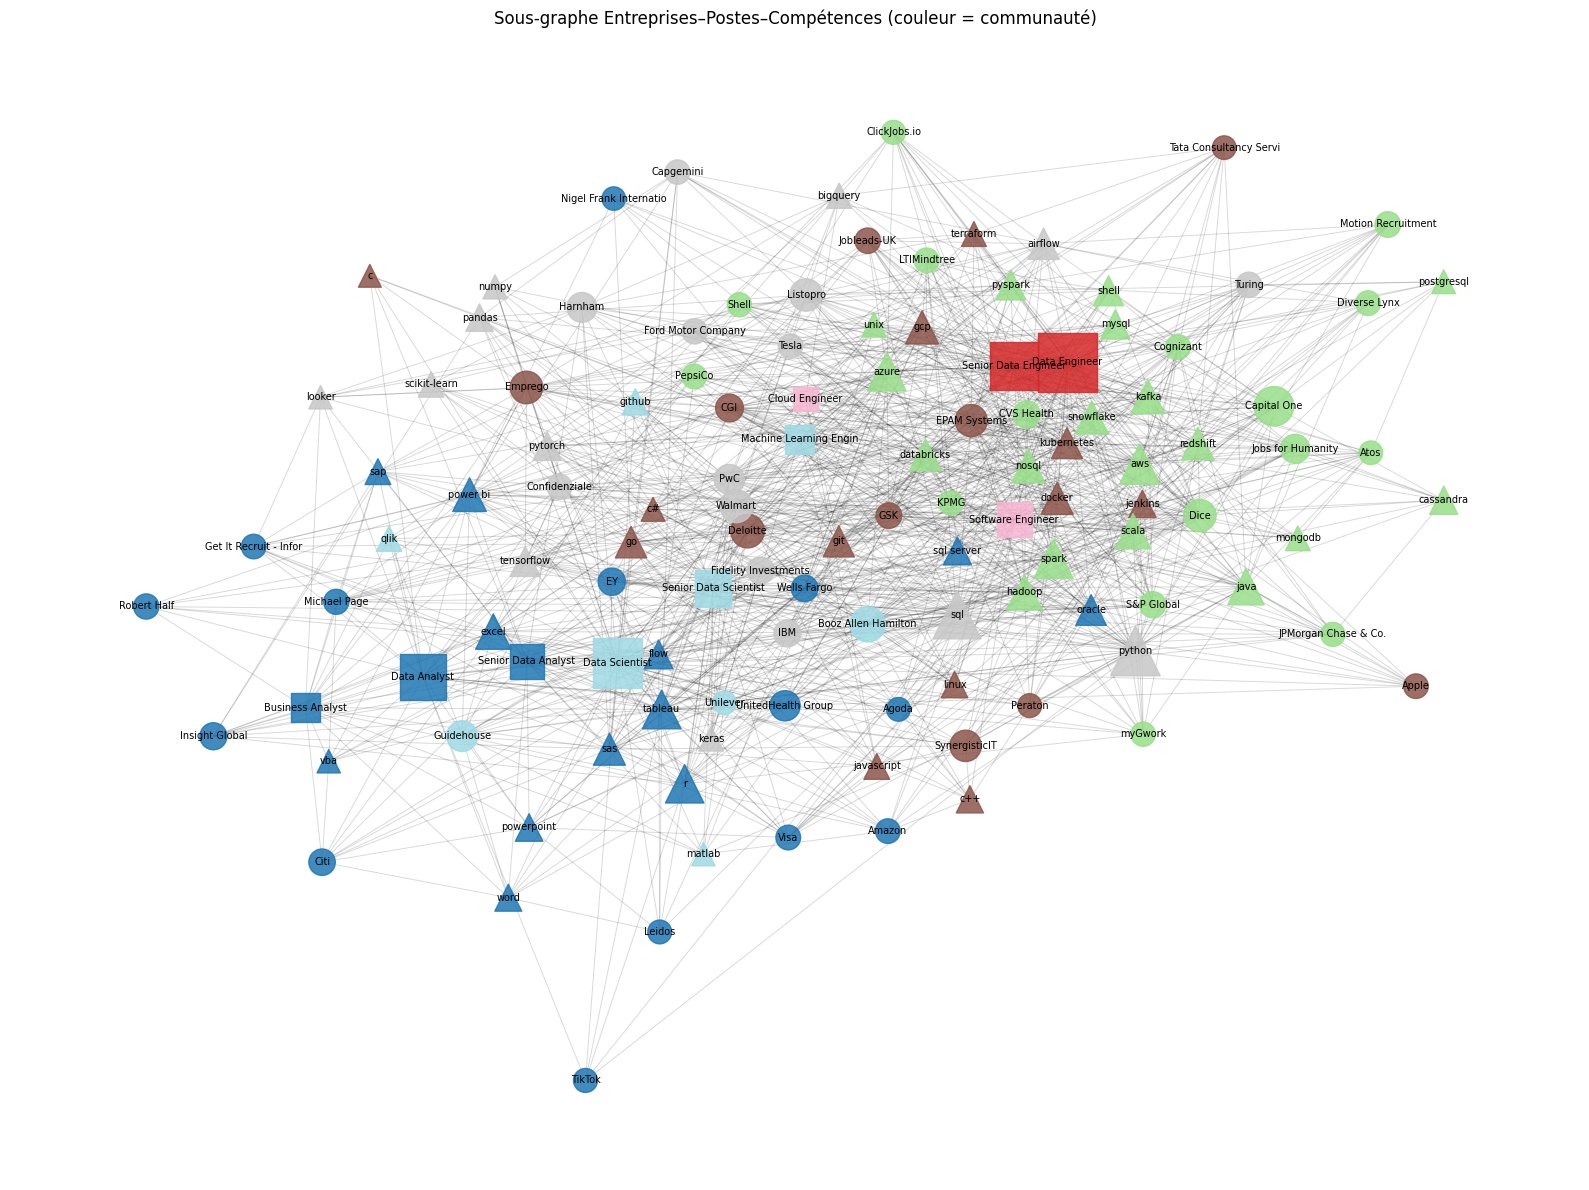

Export : graphe_entreprises_postes_competences.graphml


In [ ]:
# Visualisation lisible du graphe (sous-graphe des nœuds les plus connectés)
top_nodes = centrality_df.head(120)["node"].tolist()
B_view = B.subgraph(top_nodes).copy()
pos = nx.spring_layout(B_view, seed=SEED, k=0.6, iterations=100)
shape_map={"company":"o","job":"s","skill":"^"}
plt.figure(figsize=(16,12))
for t,shape in shape_map.items():
    nodes=[n for n in B_view if B_view.nodes[n]["node_type"]==t]
    colors=[B_view.nodes[n].get("community",0) for n in nodes]
    sizes=[80+25*np.sqrt(B_view.degree(n,weight="count")) for n in nodes]
    nx.draw_networkx_nodes(B_view,pos,nodelist=nodes,node_shape=shape,
                           node_color=colors,node_size=sizes,cmap=plt.cm.tab20,alpha=.85)
nx.draw_networkx_edges(B_view,pos,alpha=.15,width=.7)
labels={n:B_view.nodes[n]["label"][:22] for n in B_view}
nx.draw_networkx_labels(B_view,pos,labels,font_size=7)
plt.title("Sous-graphe Entreprises–Postes–Compétences (couleur = communauté)")
plt.axis("off"); plt.tight_layout(); plt.show()

nx.write_graphml(B,"graphe_entreprises_postes_competences.graphml")
print("Export : graphe_entreprises_postes_competences.graphml")

## 8. GNN — prédiction de liens Poste–Compétence avec GraphSAGE simplifié

Cette expérience implémente un **agrégateur de voisinage de type GraphSAGE en PyTorch natif**. Les caractéristiques initiales sont des embeddings SBERT des libellés + un indicateur du type de nœud. Les arêtes Poste–Compétence sont séparées en train/test ; les arêtes de test ne sont pas utilisées dans l'adjacence d'entraînement. Le modèle apprend à distinguer les liens observés des paires négatives échantillonnées.

Il s'agit d'une expérimentation pédagogique de GNN homogénéisé sur graphe hétérogène, pas d'un GTN. Un GTN complet est une extension possible, non nécessaire pour présenter un premier GNN évalué.

In [ ]:
# Préparer les nœuds et features
node_list = list(B.nodes())
node_to_id = {n:i for i,n in enumerate(node_list)}
node_labels = [B.nodes[n]["label"] for n in node_list]
node_text_emb = sbert.encode(node_labels, batch_size=128, convert_to_numpy=True,
                             normalize_embeddings=True)
type_onehot = np.zeros((len(node_list),3),dtype=np.float32)
type_index={"company":0,"job":1,"skill":2}
for i,n in enumerate(node_list):
    type_onehot[i,type_index[B.nodes[n]["node_type"]]]=1
X_nodes = np.hstack([node_text_emb.astype(np.float32),type_onehot])
print("Features nœuds:",X_nodes.shape)

# Positifs pour la tâche cible : liens Job-Skill
positive_edges=[]
for u,v,d in B.edges(data=True):
    if d["relation"]=="requires":
        if B.nodes[u]["node_type"]=="job": job_node,skill_node=u,v
        else: job_node,skill_node=v,u
        positive_edges.append((node_to_id[job_node],node_to_id[skill_node]))
positive_edges=np.array(list(dict.fromkeys(positive_edges)),dtype=int)
print("Liens job-skill:",len(positive_edges))

Features nœuds: (220, 387)
Liens job-skill: 225


In [ ]:
# Séparer les liens positifs en train/test
rng=np.random.RandomState(SEED)
perm=rng.permutation(len(positive_edges))
cut=max(1,int(.8*len(positive_edges)))
train_pos=positive_edges[perm[:cut]]
test_pos=positive_edges[perm[cut:]]
if len(test_pos)==0:
    test_pos=train_pos[-1:]; train_pos=train_pos[:-1]

# Adjacence d'entraînement : toutes les relations sauf les liens requires test
train_pos_set={tuple(sorted(x)) for x in train_pos}
A=np.zeros((len(node_list),len(node_list)),dtype=np.float32)
for u,v,d in B.edges(data=True):
    iu,iv=node_to_id[u],node_to_id[v]
    if d["relation"]=="requires" and tuple(sorted((iu,iv))) not in train_pos_set:
        continue
    A[iu,iv]=1; A[iv,iu]=1
A += np.eye(len(node_list),dtype=np.float32)
deg=A.sum(axis=1)
A_norm=(A/np.maximum(deg[:,None],1))
print("Adjacence d'entraînement:",A_norm.shape)

job_ids=[i for i,n in enumerate(node_list) if B.nodes[n]["node_type"]=="job"]
skill_ids=[i for i,n in enumerate(node_list) if B.nodes[n]["node_type"]=="skill"]
positive_set={tuple(x) for x in positive_edges}

def sample_negative(n_samples, forbidden, rng):
    out=set(); attempts=0
    while len(out)<n_samples and attempts<n_samples*100:
        j=int(rng.choice(job_ids)); s=int(rng.choice(skill_ids))
        pair=(j,s)
        if pair not in forbidden: out.add(pair)
        attempts+=1
    return np.array(list(out),dtype=int)

train_neg=sample_negative(len(train_pos),positive_set,rng)
test_neg=sample_negative(len(test_pos),positive_set,rng)
print("Positifs train/test:",len(train_pos),len(test_pos),
      "| négatifs train/test:",len(train_neg),len(test_neg))

Adjacence d'entraînement: (220, 220)
Positifs train/test: 180 45 | négatifs train/test: 180 45


In [ ]:
class SimpleGraphSAGE(nn.Module):
    def __init__(self,input_dim,hidden_dim=128):
        super().__init__()
        self.self_linear=nn.Linear(input_dim,hidden_dim)
        self.neigh_linear=nn.Linear(input_dim,hidden_dim)
        self.out_linear=nn.Linear(hidden_dim,hidden_dim)
    def forward(self,x,adj):
        neigh=adj @ x
        h=F.relu(self.self_linear(x)+self.neigh_linear(neigh))
        return F.normalize(self.out_linear(h),p=2,dim=1)

def edge_logits(z,edges):
    return (z[edges[:,0]]*z[edges[:,1]]).sum(dim=1)*5

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model=SimpleGraphSAGE(X_nodes.shape[1]).to(device)
x_tensor=torch.tensor(X_nodes,dtype=torch.float32,device=device)
a_tensor=torch.tensor(A_norm,dtype=torch.float32,device=device)
optimizer=torch.optim.Adam(model.parameters(),lr=0.005,weight_decay=1e-4)

train_pos_t=torch.tensor(train_pos,dtype=torch.long,device=device)
train_neg_t=torch.tensor(train_neg,dtype=torch.long,device=device)
test_pos_t=torch.tensor(test_pos,dtype=torch.long,device=device)
test_neg_t=torch.tensor(test_neg,dtype=torch.long,device=device)

for epoch in range(1,101):
    model.train()
    optimizer.zero_grad()
    z=model(x_tensor,a_tensor)
    pos_logits=edge_logits(z,train_pos_t)
    neg_logits=edge_logits(z,train_neg_t)
    logits=torch.cat([pos_logits,neg_logits])
    labels=torch.cat([torch.ones_like(pos_logits),torch.zeros_like(neg_logits)])
    loss=F.binary_cross_entropy_with_logits(logits,labels)
    loss.backward()
    optimizer.step()
    if epoch%20==0:
        print(f"Epoch {epoch:03d} | loss={loss.item():.4f}")

model.eval()
with torch.no_grad():
    z=model(x_tensor,a_tensor)
    test_logits=torch.cat([edge_logits(z,test_pos_t),edge_logits(z,test_neg_t)]).cpu().numpy()
    y_gnn=np.r_[np.ones(len(test_pos)),np.zeros(len(test_neg))]
    probs=1/(1+np.exp(-test_logits))
print("GNN ROC-AUC:",round(roc_auc_score(y_gnn,probs),3))
print("GNN Average Precision:",round(average_precision_score(y_gnn,probs),3))

Epoch 020 | loss=0.5762
Epoch 040 | loss=0.3700
Epoch 060 | loss=0.2581
Epoch 080 | loss=0.1693
Epoch 100 | loss=0.1412
GNN ROC-AUC: 0.907
GNN Average Precision: 0.926


**Interprétation à compléter après exécution :** comparer ROC-AUC et Average Precision à une baseline simple fondée sur la fréquence/cooccurrence. Un score élevé ne prouve pas une généralisation parfaite ; le résultat dépend de la taille du graphe, du split des arêtes et des négatifs échantillonnés.

## 9. Recommandation de compétences et évaluation

In [ ]:
# Baseline recommandation : fréquence des compétences dans une catégorie + cooccurrence avec compétences saisies.
def recommend_skills(job_category, current_skills=None, top_n=10):
    current=set(s.lower().strip() for s in (current_skills or []))
    part=df_small[df_small["job_title_short"].str.lower()==job_category.lower()]
    if part.empty:
        return pd.DataFrame(columns=["competence","score","freq_dans_poste"])
    counts=Counter(s for skills in part["skills_list"] for s in set(skills))
    total=len(part)
    rows=[]
    for skill,count in counts.items():
        if skill in current: continue
        freq=count/total
        co=0
        if current:
            co_values=[]
            for s in current:
                co_values.append(sum(1 for skills in part["skills_list"] if s in skills and skill in skills)/max(1,sum(1 for skills in part["skills_list"] if s in skills)))
            co=float(np.mean(co_values)) if co_values else 0
        score=.65*freq+.35*co if current else freq
        rows.append({"competence":skill,"score":score,"freq_dans_poste":freq})
    return pd.DataFrame(rows).sort_values("score",ascending=False).head(top_n).reset_index(drop=True)

display(recommend_skills("Data Engineer",["python","sql"],10))

,competence,score,freq_dans_poste
0,aws,0.380031,0.366582
1,azure,0.371615,0.363636
2,spark,0.334411,0.320636
3,java,0.225263,0.212645
4,scala,0.186316,0.176517
5,kafka,0.183319,0.178480
6,hadoop,0.182431,0.174161
7,airflow,0.169478,0.157667
8,snowflake,0.166685,0.157078
9,databricks,0.163220,0.156882


In [ ]:
# Évaluation simple Precision@K / Recall@K par masquage d'une compétence d'offres.
# On utilise les compétences restantes comme contexte et les compétences masquées comme vérité terrain.
def evaluate_recommender(sample_size=500, k=5):
    eligible=[i for i,ss in enumerate(df_small["skills_list"]) if len(set(ss))>=3]
    if not eligible: return {"precision@k":np.nan,"recall@k":np.nan,"n":0}
    rng=np.random.RandomState(SEED)
    chosen=rng.choice(eligible,size=min(sample_size,len(eligible)),replace=False)
    precisions=[]; recalls=[]
    for i in chosen:
        true_skills=set(df_small.at[i,"skills_list"])
        hidden={sorted(true_skills)[-1]}
        context=true_skills-hidden
        rec=recommend_skills(df_small.at[i,"job_title_short"],list(context),k)
        predicted=set(rec["competence"]) if len(rec) else set()
        precisions.append(len(predicted&hidden)/k)
        recalls.append(len(predicted&hidden)/len(hidden))
    return {"precision@k":float(np.mean(precisions)),
            "recall@k":float(np.mean(recalls)),"n":len(chosen)}

print("Évaluation baseline :",evaluate_recommender())

Évaluation baseline : {'precision@k': 0.12959999999999997, 'recall@k': 0.648, 'n': 500}


**Limite de l'évaluation :** le masquage d'une seule compétence par offre constitue un protocole simple, mais la baseline utilise des fréquences globales par catégorie. Pour une évaluation plus stricte, créer un split temporel ou un split par offre, construire les recommandations uniquement sur le train et mesurer les compétences cachées sur le test.

## 10. Mini Q&A basé sur le graphe (Graph-RAG simplifié)

Le système combine :
1. compréhension légère de la question (mots-clés + entités connues) ;
2. retrieval dans l'index des offres pour les conjonctions de compétences ;
3. retrieval dans le graphe pour les voisinages, profils et communautés ;
4. génération déterministe d'une réponse traçable.

Un LLM peut ensuite reformuler les faits récupérés, mais il ne doit pas inventer des entreprises, offres ou chiffres.

In [ ]:
# Index inversé compétence -> identifiants d'offres
skill_to_offers=defaultdict(set)
for i,skills in enumerate(df_small["skills_list"]):
    for skill in set(skills):
        skill_to_offers[skill].add(i)
known_skills=set(skill_to_offers)
known_jobs=sorted(df_small["job_title_short"].dropna().unique(),key=len,reverse=True)
known_companies=sorted(df_small["company_name"].dropna().unique(),key=len,reverse=True)

def find_mentions(question):
    q=question.lower()
    found_skills=[s for s in sorted(known_skills,key=len,reverse=True)
                  if re.search(r"(?<![\w+#.])"+re.escape(s)+r"(?![\w+#])",q)]
    found_jobs=[j for j in known_jobs if j.lower() in q]
    found_companies=[c for c in known_companies if c.lower() in q]
    return found_skills,found_jobs,found_companies

def offers_matching(skills, mode="all", job=None):
    skills=[s for s in skills if s in skill_to_offers]
    if not skills: return set()
    sets=[skill_to_offers[s] for s in skills]
    ids=set.intersection(*sets) if mode=="all" else set.union(*sets)
    if job:
        ids &= set(df_small.index[df_small["job_title_short"].str.lower()==job.lower()])
    return ids

def companies_for_skills(skills, mode="all", job=None, top_n=10):
    ids=offers_matching(skills,mode,job)
    if not ids: return pd.DataFrame()
    matched=df_small.loc[sorted(ids)]
    result=(matched.groupby("company_name").size().rename("matching_offers").to_frame())
    total=df_small["company_name"].value_counts()
    result["all_offers"]=result.index.map(total)
    result["share_pct"]=(100*result["matching_offers"]/result["all_offers"]).round(1)
    return result.sort_values(["matching_offers","share_pct"],ascending=False).head(top_n)

def graph_skills_for_job(job, top_n=15):
    node=f"J:{job}"
    if node not in B: return pd.DataFrame()
    rows=[]
    for nbr in B.neighbors(node):
        if B.nodes[nbr]["node_type"]=="skill":
            d=B[node][nbr]
            rows.append({"skill":B.nodes[nbr]["label"],"support":d["count"],"pmi":d["pmi"]})
    return pd.DataFrame(rows).sort_values(["support","pmi"],ascending=False).head(top_n)

def graph_company_profile(company, top_n=15):
    node=f"E:{company}"
    if node not in B: return None
    jobs=[]; skills=[]
    for nbr in B.neighbors(node):
        typ=B.nodes[nbr]["node_type"]
        d=B[node][nbr]
        item={"label":B.nodes[nbr]["label"],"support":d["count"]}
        if typ=="job": jobs.append(item)
        elif typ=="skill": skills.append(item)
    return {"jobs":pd.DataFrame(jobs).sort_values("support",ascending=False).head(top_n),
            "skills":pd.DataFrame(skills).sort_values("support",ascending=False).head(top_n)}

In [ ]:
def answer_question(question, top_n=8):
    q=question.lower()
    skills,jobs,companies=find_mentions(question)
    mode="any" if re.search(r"\bou\b|\bor\b",q) else "all"

    if skills and re.search(r"entreprise|soci[ée]t[ée]|company|employeur|recrut",q):
        result=companies_for_skills(skills,mode=mode,job=jobs[0] if jobs else None,top_n=top_n)
        if result.empty:
            return {"intent":"companies_by_skills","facts":"Aucune offre correspondante dans l'échantillon."}
        return {"intent":"companies_by_skills","facts":result.to_string()}

    if jobs and re.search(r"comp[ée]tence|skill|technolog|outil|requiert|demande",q):
        result=graph_skills_for_job(jobs[0],top_n)
        return {"intent":"skills_for_job","facts":result.to_string(index=False) if len(result) else "Aucune relation trouvée dans le graphe."}

    if companies:
        profile=graph_company_profile(companies[0],top_n)
        if profile is None:
            return {"intent":"company_profile","facts":"Entreprise absente du sous-graphe sélectionné."}
        return {"intent":"company_profile",
                "facts":"Postes :\n"+profile["jobs"].to_string(index=False)+"\nCompétences :\n"+profile["skills"].to_string(index=False)}

    if skills:
        ids=offers_matching(skills,mode=mode)
        if not ids: return {"intent":"skills_query","facts":"Aucune offre correspondante."}
        vc=df_small.loc[sorted(ids),"job_title_short"].value_counts().head(top_n)
        return {"intent":"jobs_by_skills","facts":vc.to_string()}

    if jobs:
        node=f"J:{jobs[0]}"
        community=B.nodes[node].get("community") if node in B else None
        return {"intent":"job_community","facts":f"Poste={jobs[0]} ; communauté={community}"}

    return {"intent":"unknown","facts":"Question non reconnue. Mentionnez une compétence, une catégorie de poste ou une entreprise présente dans le dataset."}

demo_questions=[
    "Quelles entreprises proposent des postes avec python et sql ?",
    "Quelles compétences sont demandées pour Data Engineer ?",
    "Quels postes demandent spark ou kafka ?"
]
for question in demo_questions:
    print("\nQUESTION:",question)
    print(answer_question(question)["facts"])


QUESTION: Quelles entreprises proposent des postes avec python et sql ?
                     matching_offers  all_offers  share_pct
company_name                                               
Emprego                           58         175       33.1
Capital One                       50          66       75.8
Harnham                           41          72       56.9
Listopro                          36          64       56.2
Guidehouse                        33          51       64.7
Booz Allen Hamilton               31          77       40.3
Deloitte                          29          60       48.3
Walmart                           28          44       63.6

QUESTION: Quelles compétences sont demandées pour Data Engineer ?
 skill  support      pmi
python      539 0.081918
   sql      521 0.109185
   aws      325 0.440193
 spark      298 0.509639
 azure      291 0.475975
  java      205 0.428936
 scala      190 0.609995
hadoop      179 0.499926

QUESTION: Quels postes demandent s

### 10.1 Génération optionnelle par LLM
La cellule suivante utilise un modèle local Ollama si le serveur est disponible. Elle reçoit uniquement les faits récupérés. Le système déterministe reste utilisable sans LLM.

In [ ]:
def answer_with_ollama(question, model="llama3.2"):
    retrieval=answer_question(question)
    facts=retrieval["facts"]
    prompt=(
        "Tu es un assistant d'analyse des offres d'emploi. Réponds en français en te basant "
        "EXCLUSIVEMENT sur les faits fournis. N'invente aucun nom, chiffre ou relation. "
        "Si les faits sont insuffisants, dis-le.\n\n"
        f"Question: {question}\nFaits récupérés:\n{facts}"
    )
    try:
        import requests
        response=requests.post("http://localhost:11434/api/generate",
                               json={"model":model,"prompt":prompt,"stream":False},timeout=120)
        response.raise_for_status()
        return response.json().get("response","")
    except Exception as exc:
        print("Ollama indisponible ou non configuré :",exc)
        return facts

# Exemple : décommenter si Ollama est installé et lancé localement.
# print(answer_with_ollama("Quelles entreprises proposent des postes avec python et sql ?"))

## 11. Export des modèles, résultats et données pour l'application

In [ ]:
# Sauvegarder les principaux artefacts
os.makedirs("artifacts",exist_ok=True)
joblib.dump(tfidf_clf,"artifacts/tfidf_classifier_vectorizer.joblib")
joblib.dump(classifiers["SBERT titres"],"artifacts/job_classifier_sbert.joblib")
w2v_clf.save("artifacts/word2vec_skills.model")
np.save("artifacts/sbert_title_embeddings.npy",S)
nx.write_graphml(B,"artifacts/job_market_graph.graphml")
df_small[["job_title","job_title_short","company_name","job_country","skills_list"]].to_pickle(
    "artifacts/jobs_cleaned.pkl"
)
classification_results.to_csv("artifacts/classification_metrics.csv")
community_profiles.to_csv("artifacts/community_profiles.csv")
top_skills_df.to_csv("artifacts/top_skills.csv",index=False)
print("Artefacts sauvegardés dans ./artifacts/")

Artefacts sauvegardés dans ./artifacts/


## 12. Interface Streamlit — génération d'un fichier `app.py`
La cellule crée une application simple de démonstration. Après exécution, lancer dans un terminal :
`streamlit run app.py`

L'application utilise les artefacts exportés dans le dossier `artifacts`.

In [ ]:
app_source = r'''
import streamlit as st
import pandas as pd
import networkx as nx
import joblib
from sentence_transformers import SentenceTransformer

st.set_page_config(page_title="Job Market Graph Explorer",layout="wide")
st.title("Exploration intelligente des offres d'emploi")
st.caption("NLP • Compétences • Entreprises • Graphe")

@st.cache_data
def load_data():
    return pd.read_pickle("artifacts/jobs_cleaned.pkl")

@st.cache_resource
def load_graph():
    return nx.read_graphml("artifacts/job_market_graph.graphml")

df = load_data()
G = load_graph()
tab1,tab2,tab3 = st.tabs(["Marché","Recherche","Graphe"])

with tab1:
    st.subheader("Tendances")
    c1,c2,c3=st.columns(3)
    c1.metric("Offres",f"{len(df):,}")
    c2.metric("Entreprises",f"{df.company_name.nunique():,}")
    c3.metric("Catégories",f"{df.job_title_short.nunique():,}")
    st.bar_chart(df.job_title_short.value_counts().head(15))
    skill_counts={}
    for skills in df.skills_list:
        for s in set(skills): skill_counts[s]=skill_counts.get(s,0)+1
    top=pd.Series(skill_counts).sort_values(ascending=False).head(20)
    st.bar_chart(top)

with tab2:
    st.subheader("Recherche par compétences")
    skills_text=st.text_input("Compétences séparées par des virgules", "python, sql")
    mode=st.radio("Correspondance",["Toutes (ET)","Au moins une (OU)"],horizontal=True)
    if st.button("Rechercher"):
        skills=[x.strip().lower() for x in skills_text.split(",") if x.strip()]
        mask=df.skills_list.apply(lambda xs: all(s in xs for s in skills) if mode.startswith("Toutes") else any(s in xs for s in skills))
        result=df[mask]
        st.metric("Offres correspondantes",len(result))
        display_cols=[c for c in ["job_title","company_name","job_country","skills_list"] if c in result.columns]
        st.dataframe(result[display_cols].head(100),use_container_width=True)
        st.write("Entreprises les plus présentes")
        st.dataframe(result.company_name.value_counts().head(20))

with tab3:
    st.subheader("Graphe hétérogène")
    st.write(f"{G.number_of_nodes()} nœuds • {G.number_of_edges()} relations")
    node_type=st.selectbox("Type de nœud",["company","job","skill"])
    nodes=[(n,d.get("label",n)) for n,d in G.nodes(data=True) if d.get("node_type")==node_type]
    labels=[x[1] for x in nodes]
    if labels:
        selected=st.selectbox("Sélectionner",labels)
        node=next(n for n,l in nodes if l==selected)
        neighbors=[]
        for nbr in G.neighbors(node):
            d=G[node][nbr]
            neighbors.append({"type":G.nodes[nbr].get("node_type"),
                              "label":G.nodes[nbr].get("label"),
                              "relation":d.get("relation"),
                              "support":d.get("count")})
        st.dataframe(pd.DataFrame(neighbors),use_container_width=True)
    else:
        st.info("Aucun nœud de ce type dans le graphe.")
'''
with open("app.py","w",encoding="utf-8") as f:
    f.write(app_source)
print("Fichier app.py généré.")

Fichier app.py généré.


## 13. Bilan et limites à présenter dans le rapport

### Livrables produits
- Dataset nettoyé et enrichi.
- Analyse exploratoire et tendances du marché.
- Classification des catégories de postes avec comparaison de représentations.
- Embeddings SBERT et Word2Vec.
- Clustering des postes et des compétences.
- Extraction d'entités adaptative (NER sur description si disponible, sinon extraction structurée).
- Graphe hétérogène avec statistiques et communautés Louvain.
- Expérience GNN de prédiction de liens Poste–Compétence.
- Recommandation de compétences avec métriques de base.
- Mini Q&A avec retrieval graphe/index et génération optionnelle.
- Artefacts exportés et application Streamlit.

### Limites à signaler honnêtement
1. Si aucune description libre n'est disponible, le NER complet sur texte d'offre n'est pas réalisable avec ce dataset seul.
2. Le GNN est une première expérimentation GraphSAGE simplifiée ; il ne s'agit pas d'un GTN.
3. Les résultats dépendent de l'échantillon, des seuils de construction du graphe et de la distribution du dataset.
4. Les recommandations et le Q&A doivent être évalués sur des données séparées et ne doivent pas être présentés comme des prédictions garanties du marché réel.
5. Les salaires et dates ne sont analysés que si les colonnes correspondantes existent et contiennent suffisamment de valeurs valides.

### Checklist avant soutenance
- Exécuter le notebook depuis un kernel vierge.
- Vérifier que toutes les cellules s'exécutent sans erreur.
- Sauvegarder les métriques et figures obtenues.
- Annoter manuellement un petit échantillon pour évaluer le NER si des descriptions sont disponibles.
- Comparer la baseline de recommandation au GNN.
- Préparer 5 à 10 questions QA et vérifier manuellement les faits récupérés.
- Ne pas inventer les résultats : commenter les chiffres réellement obtenus.